# Seleção de variáveis em regressão linear: excesso × critério

Este notebook mostra, com números, por que a **seleção de variáveis (feature selection)** importa em uma regressão linear.

**O experimento:**
1. Cria uma base sintética de 200 imóveis em que **sabemos a regra verdadeira** que forma o preço.
2. Monta duas versões com as mesmas linhas:
   - **Base selecionada:** só as 6 variáveis que de fato formam o preço.
   - **Base completa:** as mesmas 6 + 34 colunas redundantes ou sem sentido (40 no total).
3. Treina uma regressão linear em cada uma e compara R², RMSE, MAE, validação cruzada, VIF e os coeficientes.
4. Repete tudo em 500 bases diferentes e em bases de 100 a 5.000 imóveis.

### Como rodar

- **Requisitos:** Python 3.9+ com `numpy`, `pandas`, `scikit-learn` e `matplotlib`. Para instalar:
  `pip install numpy pandas scikit-learn matplotlib`
- Funciona no Jupyter Notebook, JupyterLab, VS Code e Google Colab.
- Rode todas as células em ordem (*Kernel → Restart & Run All*). Leva cerca de 1 minuto.
- As bases e os resultados são salvos em `.csv` na mesma pasta do notebook.

### Reprodutibilidade

Todos os sorteios usam sementes fixas, então rodar de novo gera exatamente os mesmos números. Os comentários do texto se referem a essa execução padrão. Versões muito diferentes das bibliotecas podem mudar levemente os resultados. As versões usadas aparecem logo abaixo da configuração.

## 1. Configuração

In [2]:
# %pip install numpy pandas scikit-learn matplotlib

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RepeatedKFold, cross_val_score, train_test_split

%matplotlib inline

SEMENTE = 42       # garante que os resultados sejam sempre os mesmos
N_LINHAS = 200     # número de imóveis da base principal

# ---- Onde salvar os arquivos ------------------------------------------------
# O Jupyter abre o notebook já "dentro" da pasta dele, então Path.cwd() aponta
# para a mesma pasta do .ipynb.
PASTA = Path.cwd()

# Se os arquivos forem parar em outro lugar, fixe o caminho manualmente, por exemplo:
# PASTA = Path.home() / "Documents" / "feature_selection"

# False -> todos os arquivos ficam soltos na pasta do notebook
# True  -> organiza em subpastas: dados/ e resultados/
USAR_SUBPASTAS = False
# -----------------------------------------------------------------------------

PASTA_DADOS = PASTA / "dados" if USAR_SUBPASTAS else PASTA
PASTA_RESULTADOS = PASTA / "resultados" if USAR_SUBPASTAS else PASTA
for p in [PASTA_DADOS, PASTA_RESULTADOS]:
    p.mkdir(parents=True, exist_ok=True)

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("Arquivos serão salvos em:", PASTA.resolve())

In [3]:
# Versões usadas nesta execução
import sys, sklearn, matplotlib
print("Python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)

Python       3.14.6
numpy        2.4.6
pandas       3.0.3
scikit-learn 1.9.0
matplotlib   3.11.0


## 2. A regra verdadeira do preço

Como os dados são sintéticos, definimos exatamente quanto cada característica vale. É isso que permite verificar se cada modelo **descobre a regra certa** ou só decora os dados.

Além dessas 6 variáveis, o preço recebe um ruído aleatório (desvio padrão de R$ 60 mil) que representa o que nenhum modelo consegue explicar: negociação, estado de conservação, sorte.

In [4]:
EFEITO_REAL = {
    "intercepto": 80_000,
    "area_m2": 3_200,              # cada m² adiciona R$ 3.200
    "quartos": 10_000,
    "banheiros": 18_000,
    "vagas_garagem": 22_000,
    "idade_anos": -2_500,          # cada ano de idade tira R$ 2.500
    "distancia_centro_km": -6_000, # cada km do centro tira R$ 6.000
}
VARIAVEIS_SELECIONADAS = [c for c in EFEITO_REAL if c != "intercepto"]
RUIDO = 60_000

## 3. Gerando a base

A função cria as 6 variáveis reais e, em seguida, as 34 variáveis em excesso:

- **Redundantes:** a mesma informação de outro jeito (área em pés², idade em meses, distância em milhas...).
- **Sem relação com o preço:** ID do anúncio, número da porta, cor da fachada, signo do proprietário...

In [5]:
def gerar_base(n: int, semente: int, ruido: float = RUIDO) -> pd.DataFrame:
    # Gera uma base de imóveis com as variáveis reais e as variáveis em excesso.
    rng = np.random.default_rng(semente)

    # Variáveis que de fato formam o preço
    area = np.clip(rng.lognormal(np.log(105), 0.42, n), 35, 350).round(0)
    quartos = np.clip(np.round(area / 40 + rng.normal(0, 0.6, n)), 1, 5)
    banheiros = np.clip(np.round(quartos * 0.6 + rng.normal(0, 0.6, n)), 1, 4)
    vagas = np.clip(np.round(area / 80 + rng.normal(0, 0.7, n)), 0, 4)
    idade = rng.uniform(0, 40, n).round(0)
    distancia = np.clip(rng.gamma(2.2, 3.0, n), 0.3, 25).round(1)

    preco = (
        EFEITO_REAL["intercepto"]
        + EFEITO_REAL["area_m2"] * area
        + EFEITO_REAL["quartos"] * quartos
        + EFEITO_REAL["banheiros"] * banheiros
        + EFEITO_REAL["vagas_garagem"] * vagas
        + EFEITO_REAL["idade_anos"] * idade
        + EFEITO_REAL["distancia_centro_km"] * distancia
        + rng.normal(0, ruido, n)  # o que nenhum modelo consegue explicar
    )

    df = pd.DataFrame({
        "area_m2": area,
        "quartos": quartos,
        "banheiros": banheiros,
        "vagas_garagem": vagas,
        "idade_anos": idade,
        "distancia_centro_km": distancia,
    })

    # Variáveis redundantes (a mesma informação, de outro jeito)
    df["area_pes2"] = (area * 10.764 + rng.normal(0, 4, n)).round(0)
    df["area_total_m2"] = (area * rng.uniform(1.05, 1.30, n)).round(0)
    df["idade_meses"] = idade * 12 + rng.integers(0, 12, n)
    df["distancia_centro_milhas"] = (distancia / 1.609 + rng.normal(0, 0.03, n)).round(2)
    df["total_comodos"] = quartos + banheiros + 2 + rng.integers(0, 3, n)

    # Variáveis sem relação com o preço
    df["id_anuncio"] = np.arange(1, n + 1) + 10_000
    df["numero_imovel"] = rng.integers(1, 3_000, n)
    df["fotos_no_anuncio"] = rng.integers(3, 41, n)
    df["dias_anunciado"] = rng.integers(1, 180, n)
    df["temperatura_dia_visita"] = rng.normal(24, 4, n).round(1)
    df["letras_nome_rua"] = rng.integers(5, 31, n)
    df["idade_corretor"] = rng.integers(22, 66, n)
    categoricas = {
        "cor_fachada": ["branca", "bege", "cinza", "amarela", "azul", "verde"],
        "signo_proprietario": ["aries", "touro", "gemeos", "cancer", "leao", "virgem",
                               "libra", "escorpiao", "sagitario", "capricornio",
                               "aquario", "peixes"],
        "dia_semana_anuncio": ["seg", "ter", "qua", "qui", "sex", "sab", "dom"],
    }
    for nome, categorias in categoricas.items():
        valores = rng.choice(categorias, n)
        for cat in categorias[1:]:  # one-hot, deixando a 1ª categoria como referência
            df[f"{nome}_{cat}"] = (valores == cat).astype(int)

    df["preco"] = preco.round(-2)
    return df

In [6]:
base = gerar_base(N_LINHAS, SEMENTE)
TODAS = [c for c in base.columns if c != "preco"]

base_selecionada = base[VARIAVEIS_SELECIONADAS + ["preco"]]
base.to_csv(PASTA_DADOS / "base_completa.csv", index=False)
base_selecionada.to_csv(PASTA_DADOS / "base_selecionada.csv", index=False)

print(f"Base completa:    {base.shape[0]} linhas × {len(TODAS)} variáveis")
print(f"Base selecionada: {base_selecionada.shape[0]} linhas × {len(VARIAVEIS_SELECIONADAS)} variáveis")
base.head()

Base completa:    200 linhas × 40 variáveis
Base selecionada: 200 linhas × 6 variáveis


,area_m2,quartos,banheiros,vagas_garagem,idade_anos,distancia_centro_km,area_pes2,area_total_m2,idade_meses,distancia_centro_milhas,...,signo_proprietario_capricornio,signo_proprietario_aquario,signo_proprietario_peixes,dia_semana_anuncio_ter,dia_semana_anuncio_qua,dia_semana_anuncio_qui,dia_semana_anuncio_sex,dia_semana_anuncio_sab,dia_semana_anuncio_dom,preco
0,119.000,3.000,2.000,2.000,24.000,7.200,"1,277.000",130.000,299.000,4.500,...,0,0,0,0,1,0,0,0,0,"383,000.000"
1,68.000,3.000,2.000,0.000,22.000,6.100,732.000,82.000,275.000,3.770,...,0,0,0,0,1,0,0,0,0,"343,000.000"
2,144.000,4.000,3.000,3.000,16.000,9.700,"1,555.000",163.000,200.000,5.970,...,0,0,0,0,0,0,0,0,1,"583,200.000"
3,156.000,4.000,2.000,2.000,27.000,3.100,"1,684.000",189.000,324.000,1.970,...,0,0,1,0,0,0,0,0,0,"600,900.000"
4,46.000,1.000,1.000,0.000,29.000,8.600,489.000,53.000,352.000,5.350,...,0,0,0,0,0,1,0,0,0,"101,600.000"


## 4. Por que cada variável ficou de fora

A seleção usou quatro perguntas:

1. **Faz sentido para o negócio?** Signo do proprietário não muda o preço de um imóvel.
2. **É redundante?** Área em m² e em pés² são a mesma informação.
3. **É só um identificador?** ID e número da porta não descrevem o imóvel.
4. **Os dados confirmam?** VIF, validação cruzada e desempenho fora da amostra (próximas seções).

In [7]:
JUSTIFICATIVA_EXCLUSAO = {
    "area_pes2": "Redundante: é a mesma área em pés² (correlação ~1 com area_m2)",
    "area_total_m2": "Redundante: área total é a área útil com um acréscimo",
    "idade_meses": "Redundante: é a idade em anos multiplicada por 12",
    "distancia_centro_milhas": "Redundante: mesma distância em outra unidade",
    "total_comodos": "Redundante: soma de quartos + banheiros + outros cômodos",
    "id_anuncio": "Identificador: número sequencial, sem relação com preço",
    "numero_imovel": "Sem relação plausível: número da porta",
    "fotos_no_anuncio": "Sem relação plausível com o valor do imóvel",
    "dias_anunciado": "Sem relação plausível (e pode ser consequência do preço)",
    "temperatura_dia_visita": "Sem relação plausível com o valor do imóvel",
    "letras_nome_rua": "Sem relação plausível com o valor do imóvel",
    "idade_corretor": "Característica do corretor, não do imóvel",
    "cor_fachada_*": "Sem relação plausível (5 colunas dummy)",
    "signo_proprietario_*": "Sem relação plausível (11 colunas dummy)",
    "dia_semana_anuncio_*": "Sem relação plausível (6 colunas dummy)",
}
pd.DataFrame(JUSTIFICATIVA_EXCLUSAO.items(), columns=["variável excluída", "motivo"])

,variável excluída,motivo
0,area_pes2,Redundante: é a mesma área em pés² (correlação...
1,area_total_m2,Redundante: área total é a área útil com um ac...
2,idade_meses,Redundante: é a idade em anos multiplicada por 12
3,distancia_centro_milhas,Redundante: mesma distância em outra unidade
4,total_comodos,Redundante: soma de quartos + banheiros + outr...
5,id_anuncio,"Identificador: número sequencial, sem relação ..."
6,numero_imovel,Sem relação plausível: número da porta
7,fotos_no_anuncio,Sem relação plausível com o valor do imóvel
8,dias_anunciado,Sem relação plausível (e pode ser consequência...
9,temperatura_dia_visita,Sem relação plausível com o valor do imóvel


### Confirmando com os dados: VIF por variável

O **VIF (fator de inflação da variância)** mede quanto uma variável é explicada pelas outras. Acima de 10 já indica multicolinearidade forte. Na base completa, as colunas redundantes aparecem no topo, como esperado.

In [8]:
def rmse(y, p):
    return mean_squared_error(y, p) ** 0.5


def r2_ajustado(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)


def vif_por_variavel(X: pd.DataFrame) -> pd.Series:
    # VIF de cada variável: 1 / (1 - R²) da regressão dela contra as demais.
    A = X.to_numpy(dtype=float)
    valores = {}
    for j, col in enumerate(X.columns):
        outras = np.delete(A, j, axis=1)
        r2 = LinearRegression().fit(outras, A[:, j]).score(outras, A[:, j])
        valores[col] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(valores, name="VIF").sort_values(ascending=False)


vif_completa = vif_por_variavel(base[TODAS])
vif_selecionada = vif_por_variavel(base[VARIAVEIS_SELECIONADAS])
print("Base selecionada (todas as variáveis):")
display(vif_selecionada.to_frame())
print("Base completa (10 maiores):")
display(vif_completa.head(10).to_frame())

Base selecionada (todas as variáveis):


,VIF
quartos,3.891
area_m2,3.231
banheiros,2.116
vagas_garagem,1.530
idade_anos,1.038
distancia_centro_km,1.029


Base completa (10 maiores):


,VIF
area_pes2,"16,966.703"
area_m2,"16,818.773"
distancia_centro_milhas,"9,883.692"
distancia_centro_km,"9,876.553"
idade_meses,"2,186.900"
idade_anos,"2,175.626"
area_total_m2,48.035
quartos,6.584
total_comodos,5.790
banheiros,3.835


## 5. Treinando e comparando os dois modelos

Mesma regressão linear (mínimos quadrados, sem regularização), mesmos dados e **mesma divisão** treino/teste (70% / 30%) para os dois modelos. A validação cruzada usa 5 partes repetidas 20 vezes.

In [9]:
def treinar_e_avaliar(df, colunas, semente=SEMENTE):
    X, y = df[colunas], df["preco"]
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=semente)
    modelo = LinearRegression().fit(X_tr, y_tr)
    p_tr, p_te = modelo.predict(X_tr), modelo.predict(X_te)
    r2_tr, r2_te = r2_score(y_tr, p_tr), r2_score(y_te, p_te)

    cv = RepeatedKFold(n_splits=5, n_repeats=20, random_state=semente)
    rmse_cv = -cross_val_score(LinearRegression(), X, y, cv=cv,
                               scoring="neg_root_mean_squared_error")
    metricas = {
        "n_variaveis": len(colunas),
        "r2_treino": r2_tr,
        "r2_teste": r2_te,
        "queda_r2_treino_teste": r2_tr - r2_te,
        "r2_ajustado_treino": r2_ajustado(r2_tr, len(y_tr), len(colunas)),
        "rmse_treino": rmse(y_tr, p_tr),
        "rmse_teste": rmse(y_te, p_te),
        "mae_teste": mean_absolute_error(y_te, p_te),
        "rmse_cv_media": rmse_cv.mean(),
        "rmse_cv_desvio": rmse_cv.std(),
        "vif_maximo": vif_por_variavel(X).max(),
        "coef_area_m2": modelo.coef_[list(colunas).index("area_m2")],
        "coef_distancia_km": modelo.coef_[list(colunas).index("distancia_centro_km")],
    }
    return metricas, modelo


met_sel, modelo_sel = treinar_e_avaliar(base, VARIAVEIS_SELECIONADAS)
met_com, modelo_com = treinar_e_avaliar(base, TODAS)
res = pd.DataFrame({"selecionada": met_sel, "completa": met_com})
res

,selecionada,completa
n_variaveis,6.000,40.000
r2_treino,0.895,0.920
r2_teste,0.833,0.755
queda_r2_treino_teste,0.062,0.165
r2_ajustado_treino,0.890,0.888
rmse_treino,"61,610.329","53,568.667"
rmse_teste,"63,667.662","77,059.493"
mae_teste,"49,274.030","63,852.283"
rmse_cv_media,"63,894.921","73,600.664"
rmse_cv_desvio,"5,811.599","5,675.603"


**Como ler:** no treino o modelo com 40 variáveis parece melhor (R² maior, RMSE menor), mas no teste ele perde em todas as métricas. Isso é **overfitting**: com 40 colunas e só 140 imóveis de treino, o modelo usa as colunas sem sentido para decorar o ruído.

## 6. O modelo descobriu a regra certa?

Comparando os coeficientes estimados com os valores reais usados para gerar o preço:

In [10]:
coefs = pd.DataFrame({
    "valor real": {v: EFEITO_REAL[v] for v in VARIAVEIS_SELECIONADAS},
    "6 selecionadas": dict(zip(VARIAVEIS_SELECIONADAS, modelo_sel.coef_)),
    "40 (excesso)": dict(zip(TODAS, modelo_com.coef_)),
}).loc[VARIAVEIS_SELECIONADAS]
coefs.round(0).astype(int)

,valor real,6 selecionadas,40 (excesso)
area_m2,3200,2992,-31476
quartos,10000,25711,32222
banheiros,18000,9825,6567
vagas_garagem,22000,14184,12985
idade_anos,-2500,-2421,6824
distancia_centro_km,-6000,-5303,-13455


O modelo enxuto chega perto dos valores reais. O modelo com excesso estima um valor **negativo** para o m²: como área em m², em pés² e área total estão juntas, o efeito da área se espalha entre colunas que dizem a mesma coisa. O mesmo acontece com a distância (km e milhas).

Para medir a incerteza, o **bootstrap** reajusta o modelo em 2.000 reamostras da base de treino e calcula o intervalo de 95% do coeficiente da área:

In [11]:
def bootstrap_coef(df, colunas, variavel, n_boot=2000, semente=SEMENTE):
    # Intervalo de 95% do coeficiente de uma variável, reamostrando a base de treino.
    rng = np.random.default_rng(semente)
    treino, _ = train_test_split(df, test_size=0.3, random_state=semente)  # mesma divisão do modelo
    X, y = treino[colunas].to_numpy(float), treino["preco"].to_numpy(float)
    j = list(colunas).index(variavel)
    coefs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        coefs.append(LinearRegression().fit(X[idx], y[idx]).coef_[j])
    return np.percentile(coefs, [2.5, 97.5])


ic_sel = bootstrap_coef(base, VARIAVEIS_SELECIONADAS, "area_m2")
ic_com = bootstrap_coef(base, TODAS, "area_m2")
res.loc["coef_area_ic95_inf"] = [ic_sel[0], ic_com[0]]
res.loc["coef_area_ic95_sup"] = [ic_sel[1], ic_com[1]]
res.loc[["coef_area_m2", "coef_area_ic95_inf", "coef_area_ic95_sup"]]

,selecionada,completa
coef_area_m2,"2,991.559","-31,475.673"
coef_area_ic95_inf,"2,587.232","-69,162.541"
coef_area_ic95_sup,"3,424.059","8,671.375"


## 7. Foi sorte? Repetindo em 500 bases diferentes

Cada simulação gera uma base nova (outra semente), divide em treino/teste e treina os dois modelos.

In [12]:
def simulacoes(n_sim=500, n=N_LINHAS):
    linhas = []
    for s in range(n_sim):
        d = gerar_base(n, 10_000 + s)
        todas = [c for c in d.columns if c != "preco"]
        X_tr, X_te, y_tr, y_te = train_test_split(d, d["preco"], test_size=0.3, random_state=s)
        for nome, cols in [("selecionada", VARIAVEIS_SELECIONADAS), ("completa", todas)]:
            m = LinearRegression().fit(X_tr[cols], y_tr)
            linhas.append({"simulacao": s, "base": nome,
                           "r2_teste": r2_score(y_te, m.predict(X_te[cols])),
                           "rmse_teste": rmse(y_te, m.predict(X_te[cols]))})
    return pd.DataFrame(linhas)


sim = simulacoes()
piv = sim.pivot(index="simulacao", columns="base", values="rmse_teste")
vitorias = (piv["selecionada"] < piv["completa"]).mean()
res.loc["r2_teste_medio_500_sim"] = sim.groupby("base")["r2_teste"].mean()[["selecionada", "completa"]].values
res.loc["rmse_teste_medio_500_sim"] = sim.groupby("base")["rmse_teste"].mean()[["selecionada", "completa"]].values

print(f"A base selecionada teve menor erro de teste em {vitorias:.1%} das 500 simulações")
res.loc[["r2_teste_medio_500_sim", "rmse_teste_medio_500_sim"]]

A base selecionada teve menor erro de teste em 98.8% das 500 simulações


,selecionada,completa
r2_teste_medio_500_sim,0.903,0.871
rmse_teste_medio_500_sim,"61,364.385","70,904.145"


## 8. E com mais dados?

Mesmo experimento com bases de 100 a 5.000 imóveis, 200 repetições para cada tamanho. Olhamos o erro de teste e a faixa central (90%) do coeficiente da área.

In [13]:
def curva_tamanho_amostra(tamanhos=(100, 200, 500, 1000, 2000, 5000), n_rep=200):
    linhas = []
    for n in tamanhos:
        for s in range(n_rep):
            d = gerar_base(n, 50_000 + s)
            todas = [c for c in d.columns if c != "preco"]
            X_tr, X_te, y_tr, y_te = train_test_split(d, d["preco"], test_size=0.3, random_state=s)
            for nome, cols in [("selecionada", VARIAVEIS_SELECIONADAS), ("completa", todas)]:
                m = LinearRegression().fit(X_tr[cols], y_tr)
                linhas.append({"n_linhas": n, "base": nome,
                               "rmse_teste": rmse(y_te, m.predict(X_te[cols])),
                               "coef_area_m2": m.coef_[cols.index("area_m2")]})
    return pd.DataFrame(linhas)


curva = curva_tamanho_amostra().groupby(["n_linhas", "base"]).agg(
    rmse_teste_medio=("rmse_teste", "mean"),
    coef_area_p05=("coef_area_m2", lambda v: np.percentile(v, 5)),
    coef_area_p95=("coef_area_m2", lambda v: np.percentile(v, 95)),
).reset_index()

# salva todos os resultados
res.to_csv(PASTA_RESULTADOS / "metricas.csv")
sim.to_csv(PASTA_RESULTADOS / "simulacoes.csv", index=False)
curva.to_csv(PASTA_RESULTADOS / "curva_tamanho_amostra.csv", index=False)
curva

,n_linhas,base,rmse_teste_medio,coef_area_p05,coef_area_p95
0,100,completa,"93,138.884","-52,909.095","45,328.380"
1,100,selecionada,"63,652.167","2,730.211","3,693.377"
2,200,completa,"71,332.532","-22,991.525","28,304.495"
3,200,selecionada,"61,218.324","2,874.852","3,553.195"
4,500,completa,"63,526.716","-13,381.686","17,830.563"
5,500,selecionada,"60,345.638","3,009.823","3,431.984"
6,1000,completa,"61,897.888","-5,584.401","13,064.298"
7,1000,selecionada,"60,329.338","3,027.504","3,340.963"
8,2000,completa,"60,934.273","-5,638.869","10,474.274"
9,2000,selecionada,"60,202.667","3,115.194","3,303.269"


Com mais dados, o erro dos dois modelos se aproxima do limite imposto pelo ruído. Mas o coeficiente da área do modelo com excesso continua disperso: **mais dados diminuem o problema de previsão, mas não resolvem o de interpretação.**

## 9. Visualizando os resultados

In [14]:
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"   # azul = selecionada, laranja = excesso
NOME_SEL, NOME_COM = "6 variáveis selecionadas", "40 variáveis (excesso)"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "axes.axisbelow": True,
    "figure.dpi": 110,
})
try:
    plt.rcParams["text.parse_math"] = False  # para "R$" não virar fórmula
except KeyError:
    pass


def num(v, casas=3):
    # Número no formato brasileiro: 1.234,567
    s = f"{abs(v):,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"−{s}" if v < 0 else s


def brl(v, casas=0):
    return ("−" if v < 0 else "") + "R$ " + num(abs(v), casas)


def pct(v, casas=1):
    return num(v * 100, casas) + "%"


S, C = res["selecionada"], res["completa"]

### Treino × teste

O R² mede quanto da variação do preço o modelo explica (1 = tudo). O modelo com excesso fica melhor no treino e pior no teste: é o sinal clássico de overfitting.

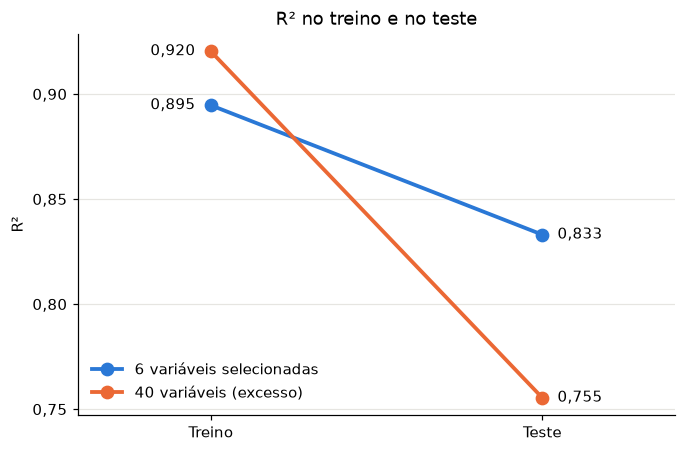

In [15]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for serie, cor, nome in [(S, AZUL, NOME_SEL), (C, LARANJA, NOME_COM)]:
    ys = [serie.r2_treino, serie.r2_teste]
    ax.plot([0, 1], ys, color=cor, lw=2.5, marker="o", markersize=8, label=nome)
    ax.annotate(num(ys[0]), (0, ys[0]), xytext=(-10, 0), textcoords="offset points", ha="right", va="center")
    ax.annotate(num(ys[1]), (1, ys[1]), xytext=(10, 0), textcoords="offset points", ha="left", va="center")
ax.set_xticks([0, 1], ["Treino", "Teste"])
ax.set_xlim(-0.4, 1.4)
ax.grid(axis="x", visible=False)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(lambda v, _: num(v, 2))
ax.set_ylabel("R²")
ax.set_title("R² no treino e no teste")
ax.legend(frameon=False, loc="lower left")
plt.show()

### O modelo aprendeu o valor certo do m²?

Ponto = coeficiente estimado; faixa = intervalo de 95% (bootstrap). A linha preta é o valor real usado para gerar os preços.

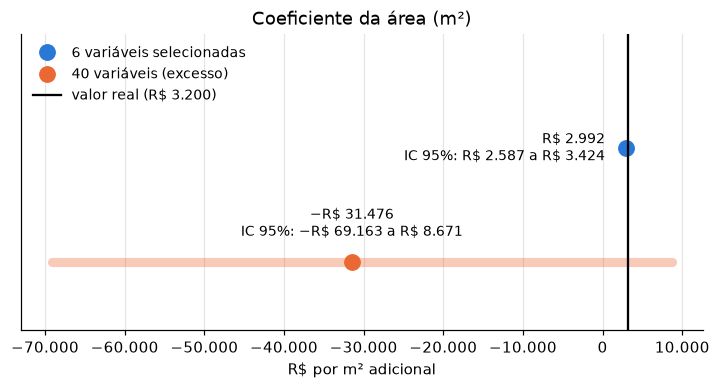

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
# rótulo do enxuto à esquerda do ponto; do excesso, acima da faixa
posicao = {1: dict(xytext=(-14, 0), ha="right", va="center"),
           0: dict(xytext=(0, 14), ha="center", va="bottom")}
for y, serie, cor, nome in [(1, S, AZUL, NOME_SEL), (0, C, LARANJA, NOME_COM)]:
    ax.plot([serie.coef_area_ic95_inf, serie.coef_area_ic95_sup], [y, y], color=cor, lw=6,
            alpha=0.35, solid_capstyle="round")
    ax.plot(serie.coef_area_m2, y, "o", color=cor, markersize=10, label=nome)
    ax.annotate(f"{brl(serie.coef_area_m2)}\nIC 95%: {brl(serie.coef_area_ic95_inf)} a {brl(serie.coef_area_ic95_sup)}",
                (serie.coef_area_m2, y), textcoords="offset points", fontsize=9, **posicao[y])
ax.axvline(EFEITO_REAL["area_m2"], color="black", lw=1.5, label=f"valor real ({brl(EFEITO_REAL['area_m2'])})")
ax.set_yticks([])
ax.set_ylim(-0.6, 2.0)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda v, _: num(v, 0))
ax.set_xlabel("R$ por m² adicional")
ax.set_title("Coeficiente da área (m²)")
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.show()

### Em quantas das 500 bases o modelo enxuto errou menos?

Cada barra conta as simulações por diferença de erro. À direita do zero, o modelo com excesso errou mais.

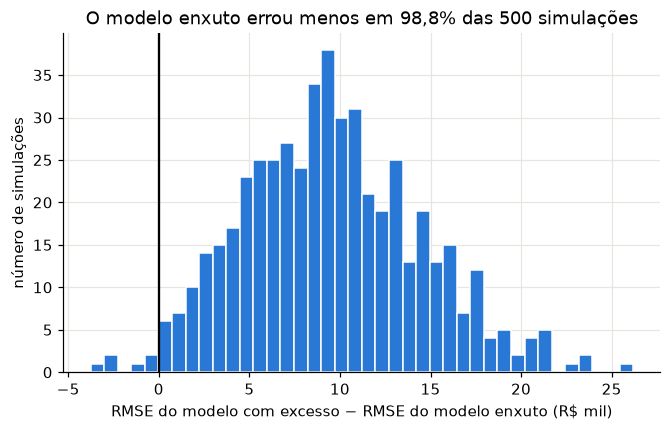

In [17]:
diferenca = (piv["completa"] - piv["selecionada"]) / 1000
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(diferenca, bins=40, color=AZUL, edgecolor="white")
ax.axvline(0, color="black", lw=1.5)
ax.set_xlabel("RMSE do modelo com excesso − RMSE do modelo enxuto (R$ mil)")
ax.set_ylabel("número de simulações")
ax.set_title(f"O modelo enxuto errou menos em {pct(vitorias)} das {len(piv)} simulações")
plt.show()

### Efeito do tamanho da base

Erro médio no teste conforme a base cresce. A linha cinza é o ruído, o erro que nenhum modelo consegue eliminar.

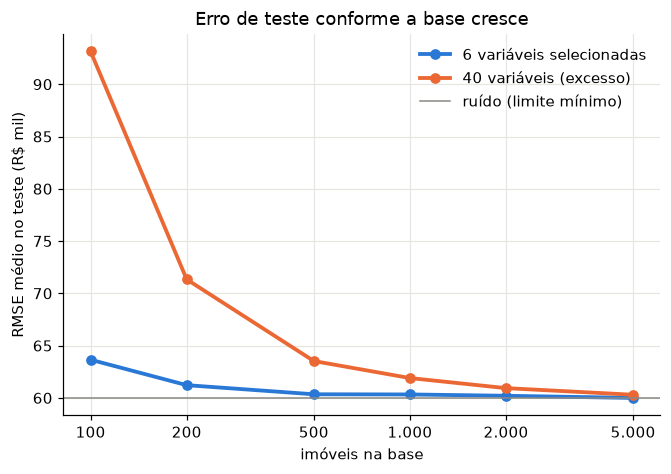

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for nome, cor, rotulo in [("selecionada", AZUL, NOME_SEL), ("completa", LARANJA, NOME_COM)]:
    d = curva[curva.base == nome].sort_values("n_linhas")
    ax.plot(d.n_linhas, d.rmse_teste_medio / 1000, color=cor, lw=2.5, marker="o", label=rotulo)
ax.axhline(RUIDO / 1000, color=CINZA, lw=1, label="ruído (limite mínimo)")
ax.set_xscale("log")
ns = sorted(curva.n_linhas.unique())
ax.set_xticks(ns, [num(n, 0) for n in ns])
ax.minorticks_off()
ax.set_xlabel("imóveis na base")
ax.set_ylabel("RMSE médio no teste (R$ mil)")
ax.set_title("Erro de teste conforme a base cresce")
ax.legend(frameon=False)
plt.show()

## 10. Resumo dos resultados

In [19]:
print(f"R² no treino:  selecionada {num(S.r2_treino)} | excesso {num(C.r2_treino)}")
print(f"R² no teste:   selecionada {num(S.r2_teste)} | excesso {num(C.r2_teste)}")
print(f"RMSE no teste: selecionada {brl(S.rmse_teste)} | excesso {brl(C.rmse_teste)} "
      f"(+{pct(C.rmse_teste / S.rmse_teste - 1, 0)})")
print(f"Validação cruzada: o modelo com excesso erra +{pct(C.rmse_cv_media / S.rmse_cv_media - 1, 0)}")
print(f"{len(piv)} simulações: o modelo enxuto errou menos em {pct(vitorias)} delas")
print(f"Valor do m² (real {brl(EFEITO_REAL['area_m2'])}): selecionada {brl(S.coef_area_m2)} | excesso {brl(C.coef_area_m2)}")
print(f"VIF máximo: selecionada {num(S.vif_maximo, 1)} | excesso {num(C.vif_maximo, 0)}")

print("\nArquivos gerados:")
for arq in sorted(PASTA.rglob("*.csv")):
    print("  ", arq.relative_to(PASTA))

R² no treino:  selecionada 0,895 | excesso 0,920
R² no teste:   selecionada 0,833 | excesso 0,755
RMSE no teste: selecionada R$ 63.668 | excesso R$ 77.059 (+21%)
Validação cruzada: o modelo com excesso erra +15%
500 simulações: o modelo enxuto errou menos em 98,8% delas
Valor do m² (real R$ 3.200): selecionada R$ 2.992 | excesso −R$ 31.476
VIF máximo: selecionada 3,9 | excesso 16.967

Arquivos gerados:
   base_completa.csv
   base_selecionada.csv
   curva_tamanho_amostra.csv
   metricas.csv
   simulacoes.csv


## 11. Conclusões

- **A métrica de treino engana.** Mais colunas quase sempre aumentam o R² de treino, mesmo quando são ruído puro. O que importa é o desempenho em dados que o modelo nunca viu.
- **Variáveis sem sentido causam overfitting.** Com poucas observações por variável, o modelo usa colunas aleatórias para decorar o ruído do treino.
- **Variáveis redundantes destroem a interpretação.** Quando duas colunas dizem a mesma coisa (área em m² e em pés²), o modelo não consegue separar o efeito de cada uma, e os coeficientes perdem o sentido.
- **Mais dados ajudam a prever, mas não a explicar.** Com bases grandes o erro se aproxima, mas os coeficientes do modelo com excesso continuam instáveis.
- **Na vida real ninguém conhece a regra verdadeira.** Por isso a seleção combina conhecimento do negócio (a variável faz sentido? é redundante? é só um identificador?) com validação estatística (VIF, validação cruzada, teste fora da amostra).

## 12. Experimente

Mude os parâmetros e rode tudo de novo (*Kernel → Restart & Run All*):

- `N_LINHAS` (seção 1): com 1.000 ou 5.000 imóveis, o modelo com excesso melhora na previsão, mas e os coeficientes?
- `RUIDO` (seção 2): com menos ruído, o overfitting fica menor ou maior?
- `SEMENTE` (seção 1): veja que a conclusão se mantém com outros sorteios.
- `VARIAVEIS_SELECIONADAS` (seção 2): acrescente `"area_pes2"` à lista e observe o VIF e o coeficiente da área.
- Troque `LinearRegression` por `Ridge` ou `Lasso` (de `sklearn.linear_model`) e compare: a regularização compensa parte do excesso de variáveis?